# 04 · LLM в каскаде: только для пропусков, с проверкой цитаты

Продолжение [`03_hybrids`](03_hybrids.ipynb). LLM — последняя и самая дорогая ступень каскада. Правила вызова:

1. **Когда спрашиваем.** Только для слотов категории, по которым дешёвые источники не дали уверенного текстового кандидата.
2. **Что спрашиваем.** Только характеристики, которые на val хотя бы иногда упоминаются в тексте (подтверждаемость ≥ 15%). Страну или гарантию у LLM не спрашиваем: в тексте их нет, будет галлюцинация.
3. **Как проверяем.** Ответ обязан содержать дословную цитату. Цитата ищется в карточке, значение — в цитате. Не нашлось — значение отбрасывается.
4. **Какая уверенность.** Значения только от LLM получают уверенность, равную их точности на val по типу характеристики.
5. **Какие карточки.** Маршрутизация: LLM вызывается, только если ожидаемое число находимых полей (сумма долей подтверждаемости непокрытых слотов) не ниже порога. Порог выбирается на val так, чтобы доля вызовов была ≤ 30% (гейт `llm_share` из `docs/DATA_CONTRACT.md`).

**Модель.** Локальная открытая Qwen3-8B (Apache 2.0) в 4 битах на RTX 4060 8 ГБ, режим рассуждений выключен. Тот же код работает со шлюзом хакатона и с vLLM на ВМ: `attrx.local_llm.LocalChat` повторяет интерфейс OpenAI `chat.completions`.

**Выборки.** Генерация дорогая, поэтому выборки меньше `test_core`, но из того же распределения:
- `val_llm` — для калибровки;
- `test_llm` — для сравнения.

Все конфигурации сравниваются на одних и тех же карточках.

In [1]:
import json, os, time
from pathlib import Path

import polars as pl

from attrx.catalog import DataPaths, load
from attrx import metrics as M
from attrx.llm_fill import LLMFiller
from attrx.train import assign_status, status_summary, load_artifact
from attrx.cli_real import CONFIGS as STACKS, MAIN

candidates = [os.environ.get("ATTRX_DATA_DIR"), "../data/real", str(Path.home() / "hackathon_data")]
DATA_DIR = next(Path(p) for p in candidates if p and (Path(p) / "cu_ws").exists())
P = DataPaths(DATA_DIR)
MODEL_PATH = os.environ.get("ATTRX_LOCAL_LLM", str(next((DATA_DIR / "models/hf/hub/models--Qwen--Qwen3-8B/snapshots").iterdir())))
MODEL_NAME = "Qwen3-8B-nf4-local"
REPORTS, FIG = Path("../reports"), Path("../reports/figures")
pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_width_chars(180); pl.Config.set_tbl_cols(14)
cards, gold, schema, cats = (load(P, n) for n in ("cards", "gold", "schema", "categories"))
comp, verifiers = load_artifact(P, "components"), load_artifact(P, "verifiers")
ver, thr = verifiers[MAIN]
print("модель:", MODEL_PATH, "| каскад:", MAIN, "| порог accept:", round(thr, 3))

модель: C:\Users\ibrag\hackathon_data\models\hf\hub\models--Qwen--Qwen3-8B\snapshots\b968826d9c46dd6066d109eabc6255188de91218 | каскад: patterns+analogs+similar | порог accept: 0.891


## 1. Какие характеристики имеет смысл спрашивать у LLM

Считаем на val: доля эталонных значений характеристики, которые встречаются в тексте карточек категории.

In [2]:
val_all = M.eval_sample(cards, cats, "val", top_k=None, per_category=None, per_group=300)
sup_val = M.supported_flags(val_all, gold, schema).join(val_all.select("sku_id", "category_id"), on="sku_id")
rates = sup_val.group_by("category_id", "attribute").agg(pl.col("supported").mean().alias("rate"), pl.len().alias("n"))
askable = {}  # категория -> {характеристика: доля подтверждаемости на val}
for c, a, r in rates.filter((pl.col("rate") >= 0.15) & (pl.col("n") >= 5)).select("category_id", "attribute", "rate").iter_rows():
    askable.setdefault(c, {})[a] = r
n_schema = schema.filter(pl.col("category_id").is_in(list(askable))).height
print(f"категорий: {len(askable)}, характеристик к опросу: {sum(map(len, askable.values()))} из {n_schema} в их схемах")

категорий: 328, характеристик к опросу: 2685 из 8278 в их схемах


In [3]:
names = dict(cats.select("id", "name").iter_rows())
filler = LLMFiller(comp.lexicon, client=None, model=MODEL_NAME, askable=askable, category_names=names,
                   cache_dir=P.work / "llm_cache")
val_llm = M.eval_sample(cards, cats, "val", per_category=4, per_group=2)
test_llm = M.eval_sample(cards, cats, "test", per_category=6, per_group=3)
llm_only_sample = M.eval_sample(cards, cats, "test", per_category=2, per_group=1)
cascade = comp.stack(**STACKS[MAIN], verifier=ver)
cascade.gap_filler = filler
requests = {"val": cascade.llm_requests(val_llm), "test": cascade.llm_requests(test_llm)}

# LLM без каскада: спрашиваем все «текстовые» слоты (верхняя оценка качества и стоимости)
from attrx.stack import Stack
only = Stack(comp.lexicon, [], None, gap_filler=filler, gap_threshold=2.0, use_lexicon=False)
requests["llm_only"] = only.llm_requests(llm_only_sample)
for k, v in requests.items():
    n_cards = {"val": val_llm, "test": test_llm, "llm_only": llm_only_sample}[k].height
    print(f"{k:9} карточек {n_cards:4}, вызовов LLM {len(v):4} ({len(v) / n_cards:.0%}), "
          f"слотов в среднем {sum(m[1]['content'].count(chr(10) + '- ') for _, m in v) / max(len(v), 1):.1f}")

val       карточек  110, вызовов LLM  105 (95%), слотов в среднем 13.4
test      карточек  172, вызовов LLM  159 (92%), слотов в среднем 13.9
llm_only  карточек   58, вызовов LLM   53 (91%), слотов в среднем 17.1


## 2. Генерация (локальная GPU, с кэшем)

Ячейка возобновляемая: уже полученные ответы берутся из кэша. Время и токены считаются только по новым вызовам.

In [4]:
import hashlib
from attrx.local_llm import LocalChat

def cached(messages):
    digest = hashlib.sha256(json.dumps([MODEL_NAME, messages], ensure_ascii=False).encode("utf-8")).hexdigest()
    return (filler.cache_dir / f"{digest}.json").exists()

todo = [m for k in ("val", "test", "llm_only") for _, m in requests[k] if not cached(m)]
print("новых вызовов:", len(todo))
gen_stats = {"calls": 0, "prompt_tokens": 0, "completion_tokens": 0, "seconds": 0.0}
if todo:
    llm = LocalChat(MODEL_PATH)
    BATCH = 4
    todo.sort(key=lambda m: len(m[1]["content"]))  # похожая длина в пакете — меньше паддинга
    t0 = time.time()
    for i in range(0, len(todo), BATCH):
        chunk = todo[i:i + BATCH]
        for m, (answer, n_in, n_out) in zip(chunk, llm.batch(chunk)):
            filler.store(m, answer)
            gen_stats["calls"] += 1; gen_stats["prompt_tokens"] += n_in; gen_stats["completion_tokens"] += n_out
        if i % 40 == 0:
            print(f"{i + len(chunk)}/{len(todo)}  {time.time() - t0:.0f} c", flush=True)
    gen_stats["seconds"] = round(time.time() - t0, 1)
    (REPORTS / "llm_generation_stats.json").write_text(json.dumps(gen_stats), encoding="utf-8")
    del llm
else:
    p = REPORTS / "llm_generation_stats.json"
    gen_stats = json.loads(p.read_text(encoding="utf-8")) if p.exists() else gen_stats
print(gen_stats)

новых вызовов: 0
{'calls': 317, 'prompt_tokens': 287994, 'completion_tokens': 98857, 'seconds': 10973.7}


## 3. Калибровка уверенности LLM на val

In [5]:
def run(stack, sample, accept=thr):
    frame = assign_status(stack.predict_frame(sample), accept, review=0.5)
    shown = frame.filter(pl.col("status") != "reject")
    return frame, M.score_pairs(shown, gold, sample, schema, M.supported_flags(sample, gold, schema))

filler.confidence = {k: 0.7 for k in ("bool", "num", "enum", "text")}
_, vp = run(cascade, val_llm, accept=2.0)
llm_rows = vp.filter((pl.col("source") == "llm") & pl.col("gold").is_not_null())
cal = llm_rows.group_by("kind").agg(pl.col("correct").mean().alias("precision"), pl.len().alias("n")).sort("kind")
print(cal)
overall = float(llm_rows["correct"].mean()) if llm_rows.height else 0.5
filler.confidence = {k: (p if n >= 10 else overall) for k, p, n in cal.iter_rows()} | {
    k: overall for k in ("bool", "num", "enum", "text") if k not in cal["kind"].to_list()}
print("уверенность LLM по типам (точность на val):", {k: round(v, 3) for k, v in filler.confidence.items()})
print("статистика проверки цитат на val:", filler.stats.as_dict())

shape: (4, 3)
┌──────┬───────────┬─────┐
│ kind ┆ precision ┆ n   │
│ ---  ┆ ---       ┆ --- │
│ str  ┆ f64       ┆ u32 │
╞══════╪═══════════╪═════╡
│ bool ┆ 0.8125    ┆ 16  │
│ enum ┆ 0.5       ┆ 2   │
│ num  ┆ 0.747475  ┆ 99  │
│ text ┆ 0.390244  ┆ 41  │
└──────┴───────────┴─────┘
уверенность LLM по типам (точность на val): {'bool': 0.812, 'enum': 0.658, 'num': 0.747, 'text': 0.39}
статистика проверки цитат на val: {'cards': 105, 'skipped': 0, 'budget_skipped': 0, 'calls': 0, 'cache_hits': 105, 'cache_misses': 0, 'retries': 0, 'prompt_tokens': 0, 'completion_tokens': 0, 'truncated': 0, 'proposed': 877, 'accepted': 353, 'rejected_ungrounded': 480, 'rejected_value': 44, 'unknown_attr': 80, 'bad_item': 0, 'no_json': 0, 'salvaged': 31, 'parse_errors': 0, 'rejected_share': 0.5975}


## 4. Маршрутизация: на каких карточках LLM окупается (val)

Без маршрутизации LLM вызывается почти для каждой карточки: хотя бы один «текстовый» слот почти всегда открыт. Это нарушает гейт `llm_share ≤ 0.30`. Для каждой карточки считаем ожидаемое число полей, которые LLM может найти: сумму долей подтверждаемости (val) по непокрытым слотам. Порог перебираем на `val_llm`. Ответы уже в кэше, поэтому перебор не требует новых вызовов.

In [6]:
no_llm = comp.stack(**STACKS[MAIN], verifier=ver)
_, base_pairs = run(no_llm, val_llm)
base = M.summarize(base_pairs).row(0, named=True)
base_tw = M.traffic_weighted_f1(base_pairs, cats)
sweep = []
for t in (0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0):
    filler.min_expected = t
    share = len(cascade.llm_requests(val_llm)) / val_llm.height
    _, pairs = run(cascade, val_llm)
    s = M.summarize(pairs).row(0, named=True)
    sweep.append({"min_expected": t, "llm_share": share, "precision": s["precision"], "recall": s["recall"], "f1": s["f1"],
                  "gain_f1": s["f1"] - base["f1"], "gain_twf1": M.traffic_weighted_f1(pairs, cats) - base_tw})
sweep = pl.DataFrame(sweep)
ok = sweep.filter(pl.col("llm_share") <= 0.30)
MIN_EXPECTED = float(ok.sort("gain_f1", descending=True)["min_expected"][0]) if ok.height else float(sweep["min_expected"].max())
filler.min_expected = 0.0
print(f"без LLM на val_llm: F1 {base['f1']:.4f}, TW-F1 {base_tw:.4f}; выбранный порог min_expected = {MIN_EXPECTED}")
sweep

без LLM на val_llm: F1 0.5930, TW-F1 0.6038; выбранный порог min_expected = 5.0


min_expected,llm_share,precision,recall,f1,gain_f1,gain_twf1
f64,f64,f64,f64,f64,f64,f64
0.0,0.954545,0.864463,0.464146,0.603996,0.010962,0.008914
0.5,0.936364,0.864463,0.464146,0.603996,0.010962,0.008914
1.0,0.927273,0.864463,0.464146,0.603996,0.010962,0.008914
1.5,0.927273,0.864463,0.464146,0.603996,0.010962,0.008914
2.0,0.918182,0.864749,0.464146,0.604066,0.011031,0.008976
2.5,0.890909,0.864749,0.464146,0.604066,0.011031,0.008976
3.0,0.818182,0.864945,0.463791,0.603813,0.010779,0.008742
3.5,0.781818,0.86499,0.463969,0.603974,0.01094,0.00891
4.0,0.709091,0.866578,0.463436,0.603909,0.010875,0.008948


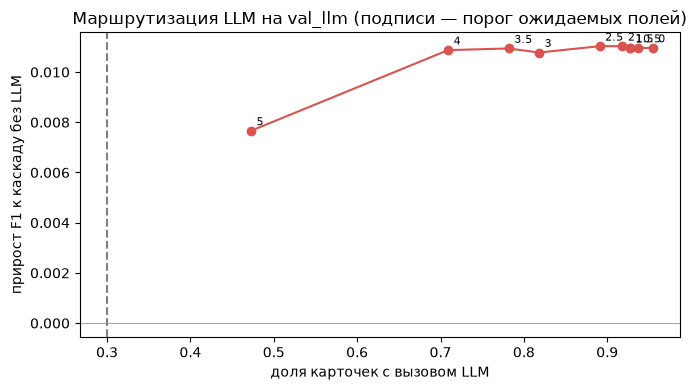

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["llm_share"], sweep["gain_f1"], "o-", c="#d9534f")
for t, x, y in sweep.select("min_expected", "llm_share", "gain_f1").iter_rows():
    ax.annotate(f"{t:g}", (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axvline(0.30, ls="--", c="gray"); ax.axhline(0, c="gray", lw=0.5)
ax.set_xlabel("доля карточек с вызовом LLM"); ax.set_ylabel("прирост F1 к каскаду без LLM")
ax.set_title("Маршрутизация LLM на val_llm (подписи — порог ожидаемых полей)")
plt.tight_layout(); plt.savefig(FIG / "llm_routing.png"); plt.show()

## 5. Сравнение на `test_llm`

In [8]:
def bench(name, stack, sample, min_expected=None):
    if min_expected is not None:
        filler.min_expected = min_expected
    calls = len(stack.llm_requests(sample)) if stack.gap_filler is not None else 0
    t = time.time(); frame, pairs = run(stack, sample); ms = 1000 * (time.time() - t) / sample.height
    s = M.summarize(pairs).row(0, named=True)
    st = {r["status"]: r for r in status_summary(pairs).iter_rows(named=True)}
    lo, hi = M.bootstrap_ci(pairs, lambda p: M.traffic_weighted_f1(p, cats), n=100)
    row = {"config": name, "cards": sample.height, "precision": s["precision"], "recall": s["recall"], "f1": s["f1"],
           "traffic_weighted_f1": M.traffic_weighted_f1(pairs, cats), "twf1_ci": f"[{lo:.3f}; {hi:.3f}]",
           "recall_supported": s["recall_supported"], "auto_fill": st.get("accept", {}).get("share_of_gold", 0),
           "precision_accept": st.get("accept", {}).get("precision"), "review_share": st.get("review", {}).get("share_of_gold", 0),
           "llm_share": calls / sample.height}
    return row, frame, pairs

ROUTED = f"8 + LLM с маршрутизацией (порог {MIN_EXPECTED:g})"
rows, test_pairs = [], {}
for name, stack, me in (("6 каскад без LLM", no_llm, None),
                        ("7 + LLM для всех пропусков", cascade, 0.0),
                        (ROUTED, cascade, MIN_EXPECTED)):
    filler.stats = type(filler.stats)()
    row, _, test_pairs[name] = bench(name, stack, test_llm, me)
    rows.append(row)
llm_fill_stats = filler.stats.as_dict()  # статистика последней конфигурации — с маршрутизацией
filler.min_expected = 0.0

# LLM без каскада на отдельной выборке; для честного сравнения там же считаем каскад без LLM
only.gap_filler = filler
for name, stack in (("6 каскад без LLM (выборка llm_only)", no_llm), ("9 только LLM, все текстовые слоты", only)):
    row, _, _ = bench(name, stack, llm_only_sample)
    rows.append(row)
llm_bench = pl.DataFrame(rows, strict=False)
llm_bench

config,cards,precision,recall,f1,traffic_weighted_f1,twf1_ci,recall_supported,auto_fill,precision_accept,review_share,llm_share
str,i64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64
"""6 каскад без LLM""",172,0.830294,0.4788,0.607359,0.61046,"""[0.575; 0.647]""",0.698803,0.051589,0.974249,0.525075,0.0
"""7 + LLM для всех пропусков""",172,0.829209,0.489649,0.615717,0.619724,"""[0.587; 0.655]""",0.759309,0.052253,0.972458,0.538249,0.924419
"""8 + LLM с маршрутизацией (порог 5)""",172,0.830121,0.486328,0.613333,0.616301,"""[0.584; 0.652]""",0.740027,0.051921,0.974414,0.533931,0.488372
"""6 каскад без LLM (выборка llm_only)""",58,0.818517,0.493029,0.615385,0.609387,"""[0.543; 0.667]""",0.711434,0.057985,0.967213,0.54436,0.0
"""9 только LLM, все текстовые слоты""",58,0.812155,0.046578,0.088103,0.086499,"""[0.065; 0.100]""",0.246824,0.0,null,0.057351,0.913793


In [9]:
print("проверка цитат на test (каскад с маршрутизацией):", llm_fill_stats)
print("по источникам:")
M.summarize(test_pairs[ROUTED].filter(pl.col("pred").is_not_null()), "source").select("source", "n_pred", "precision").filter(pl.col("n_pred") >= 10)

проверка цитат на test (каскад с маршрутизацией): {'cards': 84, 'skipped': 75, 'budget_skipped': 0, 'calls': 0, 'cache_hits': 84, 'cache_misses': 0, 'retries': 0, 'prompt_tokens': 0, 'completion_tokens': 0, 'truncated': 0, 'proposed': 753, 'accepted': 260, 'rejected_ungrounded': 427, 'rejected_value': 66, 'unknown_attr': 41, 'bad_item': 0, 'no_json': 0, 'salvaged': 24, 'parse_errors': 0, 'rejected_share': 0.6547}
по источникам:


source,n_pred,precision
str,u32,f64
"""analog""",3027,0.824579
"""similar""",1058,0.837429
"""lexicon""",189,0.571429
"""analog+lexicon""",116,0.887931
"""number""",111,0.702703
"""pattern""",102,0.676471
"""flag""",100,0.94
"""llm""",92,0.804348
"""analog+brand""",76,1.0


## 6. Стоимость

In [10]:
calls = gen_stats.get("calls") or 1
tok_in, tok_out = gen_stats["prompt_tokens"] / calls, gen_stats["completion_tokens"] / calls
sec = gen_stats["seconds"] / calls if gen_stats.get("seconds") else float("nan")
print(f"токенов на вызов: вход {tok_in:.0f}, выход {tok_out:.0f}; локальная RTX 4060 (пакет 4, 4 бита): {sec:.1f} c на вызов")
for r in llm_bench.filter(pl.col("llm_share") > 0).iter_rows(named=True):
    share = r["llm_share"]
    print(f"{r['config']:42} вызовов на карточку {share:.2f} -> на 1 000 карточек {1000 * share * (tok_in + tok_out) / 1e6:.2f} млн токенов, "
          f"{1000 * share * sec / 3600:.1f} ч GPU")

токенов на вызов: вход 908, выход 312; локальная RTX 4060 (пакет 4, 4 бита): 34.6 c на вызов
7 + LLM для всех пропусков                 вызовов на карточку 0.92 -> на 1 000 карточек 1.13 млн токенов, 8.9 ч GPU
8 + LLM с маршрутизацией (порог 5)         вызовов на карточку 0.49 -> на 1 000 карточек 0.60 млн токенов, 4.7 ч GPU
9 только LLM, все текстовые слоты          вызовов на карточку 0.91 -> на 1 000 карточек 1.12 млн токенов, 8.8 ч GPU


In [11]:
out = {"model": MODEL_NAME, "cascade": MAIN, "samples": {"val_llm": val_llm.height, "test_llm": test_llm.height, "llm_only": llm_only_sample.height},
       "rows": llm_bench.to_dicts(), "routing_sweep_val": sweep.to_dicts(), "min_expected": MIN_EXPECTED,
       "generation": gen_stats, "llm_confidence": filler.confidence, "grounding_test": llm_fill_stats}
(REPORTS / "benchmark_llm.json").write_text(json.dumps(out, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("сохранено:", REPORTS / "benchmark_llm.json")

сохранено: ..\reports\benchmark_llm.json
